<a href="https://colab.research.google.com/github/ereanoor/G1A024075_R.-Noor-Fikhri_Seminar/blob/main/Webinar_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 📊 ALUR PROSES DATA MINING & PREDICTIVE ANALYTICS
 1. Data Ingestion & Integration (Import Raw Data)
 2. Data Cleaning & Preprocessing (Handle Missing Values & Encoding)
 3. Data Splitting (Training 80% & Testing 20%)
 4. Model Training (Decision Tree / Machine Learning Classifier)
 5. Model Evaluation (Accuracy, Precision, Recall, Confusion Matrix)

📌 Sample Data Mentah (5 Baris Pertama):
   Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Berlangganan_Bulan  \
0    56             3000000          528                       12   
1    46            21000000          569                       22   
2    32            13000000          590                       17   
3    60             7000000          464                       10   
4    25            14000000          304                       54   

  Status_Kepuasan Status_Kredit  
0            Puas       Ditolak  
1            Puas       Ditolak  
2            Puas       Ditolak  
3           Cukup       Ditolak  
4           Cukup     

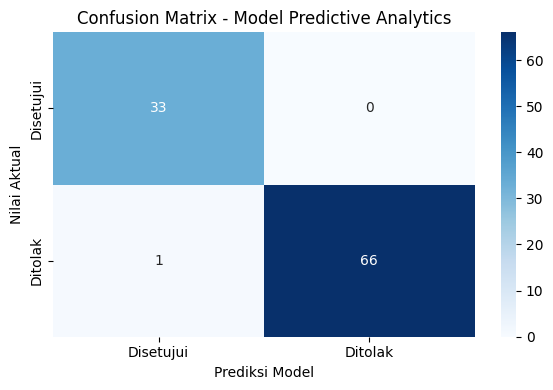


💡 KESIMPULAN MATERI 2:
 Implementasi alur Data Mining ini mempermudah ekstraksi pola dari data mentah
 menjadi prediksi keputusan yang presisi dan terukur.


In [1]:
# ==============================================================================
# INFORMATICS PRACTITIONER LECTURE SERIES 2026 - UNIB
# IMPLEMENTASI MATERI 2: Data Mining & Predictive Analytics (Pipeline & Classification)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. MENAMPILKAN SPESIFIKASI ALUR DATA MINING (DATA PIPELINE SIMULATION)
print("=" * 65)
print(" 📊 ALUR PROSES DATA MINING & PREDICTIVE ANALYTICS")
print("=" * 65)
print(" 1. Data Ingestion & Integration (Import Raw Data)")
print(" 2. Data Cleaning & Preprocessing (Handle Missing Values & Encoding)")
print(" 3. Data Splitting (Training 80% & Testing 20%)")
print(" 4. Model Training (Decision Tree / Machine Learning Classifier)")
print(" 5. Model Evaluation (Accuracy, Precision, Recall, Confusion Matrix)")
print("=" * 65 + "\n")

# 2. GENERATE SYNTHETIC DATASET (SIMULASI DATA PELANGGAN / METRICS)
np.random.seed(42)
n_samples = 500

data = {
    'Usia': np.random.randint(18, 65, size=n_samples),
    'Pendapatan_Bulanan': np.random.randint(3, 25, size=n_samples) * 1_000_000,
    'Skor_Kredit': np.random.randint(300, 850, size=n_samples),
    'Lama_Berlangganan_Bulan': np.random.randint(1, 60, size=n_samples),
    'Status_Kepuasan': np.random.choice(['Puas', 'Cukup', 'Tidak Puas'], size=n_samples)
}

df = pd.DataFrame(data)

# Menambahkan variabel target (Klasifikasi: Disetujui / Ditolak Kredit)
# Aturan logika bisnis data mining
df['Status_Kredit'] = np.where(
    (df['Skor_Kredit'] > 600) & (df['Pendapatan_Bulanan'] > 8_000_000),
    'Disetujui',
    'Ditolak'
)

print("📌 Sample Data Mentah (5 Baris Pertama):")
print(df.head(), "\n")

# 3. PREPROCESSING DATA (PREPARATION NODE)
# A. Encoding data kategorikal
le_kepuasan = LabelEncoder()
df['Status_Kepuasan_Encoded'] = le_kepuasan.fit_transform(df['Status_Kepuasan'])

le_target = LabelEncoder()
df['Status_Kredit_Target'] = le_target.fit_transform(df['Status_Kredit'])

# B. Pemisahan Fitur (X) dan Target (y)
X = df[['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Berlangganan_Bulan', 'Status_Kepuasan_Encoded']]
y = df['Status_Kredit_Target']

# C. Partitioning / Data Splitting (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# D. Feature Scaling / Normalisasi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. MODEL TRAINING (DECISION TREE CLASSIFIER NODE)
print("⏳ Melatih Model Machine Learning Classifier...")
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train_scaled, y_train)

# 5. PREDIKSI DAN EVALUASI PERFORMA
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
print(f"✅ Model Selesai Dilatih! Akurasi Model: {acc * 100:.2f}%\n")

print("=" * 65)
print(" 📈 EVALUASI DETAIL MODEL (CLASSIFICATION REPORT)")
print("=" * 65)
print(classification_report(y_test, y_pred, target_names=le_target.classes_))

# 6. VISUALISASI CONFUSION MATRIX
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le_target.classes_,
            yticklabels=le_target.classes_)
plt.title('Confusion Matrix - Model Predictive Analytics')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual')
plt.tight_layout()
plt.show()

print("\n💡 KESIMPULAN MATERI 2:")
print(" Implementasi alur Data Mining ini mempermudah ekstraksi pola dari data mentah")
print(" menjadi prediksi keputusan yang presisi dan terukur.")